# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 37: Offshore Supply Ships × Rebocadores em Representações Novas

**Autor:** Evandro Rocha (UFRJ / COPPE / PEE)
**Data:** Outubro de 2026

---

**Pergunta.** No IARA, a fronteira SMALL/MEDIUM é a mais difícil: com split por navio, nenhum modelo reconhece MEDIUM acima do acaso. O tipo mais comum de MEDIUM, o **Offshore Supply Ship (OSS)**, não difere dos **rebocadores** (SMALL) nem no LOFAR (NB35) nem no DEMON (NB36). Alguma representação que os modelos **não** usam os separa?

**Representações testadas** (extrações novas, com nomes próprios):
- **psd24k**: espectro de Welch do áudio original de 48 kHz, de 0 a 24 kHz, sem decimação (o LOFAR para em 8 kHz). Usamos a **forma** do espectro (dB menos a média da própria gravação).
- **demon_multibanda**: DEMON em cinco bandas de cavitação (0,5–1, 1–2, 2–4, 4–8 e 8–16 kHz); o DEMON do projeto usa só 1–2 kHz.
- **lofar1hz**: posição das raias estreitas persistentes (faixas de 1 Hz), uma "impressão digital" das máquinas.
- **Nível**, a partir dos blocos de 10 s do psd24k: absoluto e medidas que não dependem do ganho do equipamento.
- **MEL** do pipeline (a entrada dos modelos MEL) e **HHT** do projeto (espectro marginal e, do HHT 2D, a intermitência da energia em passos de 80 ms).

**Unidade de análise:** o navio (média das suas gravações), para que navios com muitas gravações não pesem mais. Testes de Mann-Whitney com FDR de Benjamini-Hochberg quando há muitas faixas. Para comparação, MEDIUM × SMALL (classes inteiras) e LARGE × MEDIUM.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, false_discovery_control, fisher_exact, spearmanr
from scipy.signal import find_peaks
try:
    from IPython.display import display
except ImportError:
    display = print
for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 120})
pd.set_option('display.precision', 3); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
PROC = os.path.join(R.ROOT, 'data', 'iara_processed')

meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'), dtype={'Ship ID': str, 'ID': str})
meta['Ship ID'] = meta['Ship ID'].str.strip(); meta['Length'] = pd.to_numeric(meta['Length'], errors='coerce')
meta = meta.set_index(meta.ID.astype(int))
meta = meta[meta.Dataset.isin(list('ABCD'))]                          # gravações de navio do 5x2cv (UO)
meta['classe'] = np.select([meta.Length < 50, meta.Length < 100], ['SMALL', 'MEDIUM'], 'LARGE')
GRUPOS = {'OSS (MEDIUM)': meta.index[(meta['DETAILED TYPE'] == 'Offshore Supply Ship') & (meta.Length >= 50)],
          'Tug (SMALL)': meta.index[(meta['DETAILED TYPE'] == 'Tug') & (meta.Length < 50)],
          'MEDIUM': meta.index[meta.classe == 'MEDIUM'], 'SMALL': meta.index[meta.classe == 'SMALL'],
          'LARGE': meta.index[meta.classe == 'LARGE']}
PARES = [('OSS (MEDIUM)', 'Tug (SMALL)'), ('MEDIUM', 'SMALL'), ('LARGE', 'MEDIUM')]

def nav(X, ids):
    ids = [i for i in ids if i in X.index]
    return X.loc[ids].groupby(meta.loc[ids, 'Ship ID'].values).mean()

def faixa_a_faixa(X, a, b):
    # Mann-Whitney por faixa entre as médias por navio, FDR de Benjamini-Hochberg; AUC = P(a > b)
    A, B = nav(X, GRUPOS[a]), nav(X, GRUPOS[b])
    U, p = mannwhitneyu(A.values, B.values, axis=0)
    return A, B, false_discovery_control(p), U / (len(A) * len(B))

print('Gravações e navios por grupo:')
display(pd.DataFrame({g: {'gravações': len(ix), 'navios': meta.loc[ix, 'Ship ID'].nunique(),
                          'comprimento (m)': f"{meta.loc[ix, 'Length'].min():.0f}–{meta.loc[ix, 'Length'].max():.0f}"}
                      for g, ix in GRUPOS.items()}).T)

Gravações e navios por grupo:


,gravações,navios,comprimento (m)
OSS (MEDIUM),139,46,53–93
Tug (SMALL),87,34,18–34
MEDIUM,397,82,53–98
SMALL,476,87,8–48
LARGE,572,417,100–349


## 1. Forma do espectro de 0 a 24 kHz (psd24k)

,navios,"faixas com q < 0,05",de,Δ 0.02–1 kHz (dB),Δ 1–4 kHz (dB),Δ 4–8 kHz (dB),Δ 8–16 kHz (dB),Δ 16–23 kHz (dB)
comparação,,,,,,,,
OSS (MEDIUM) × Tug (SMALL),46 × 34,0,3922,0.90,1.57,0.02,-0.40,-0.72
MEDIUM × SMALL,82 × 87,0,3922,0.04,0.10,-0.05,-0.02,-0.08
LARGE × MEDIUM,417 × 82,3355,3922,3.39,1.06,-0.08,-0.49,-0.43


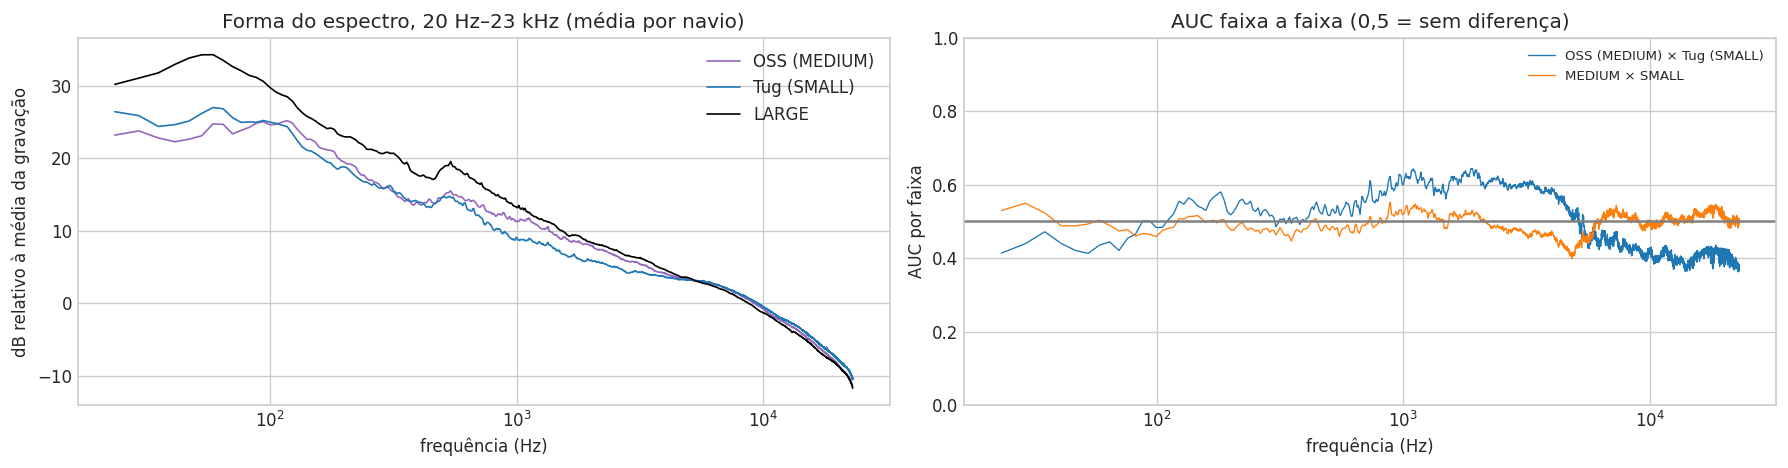

In [2]:
# psd24k: forma do espectro (dB menos a média da própria gravação em 20 Hz–20 kHz): ganho e distância viram um
# deslocamento constante e somem; sobra a distribuição da energia entre as frequências
P = pd.read_pickle(os.path.join(PROC, 'cache_psd24k_resumo.pkl'))
FP = np.asarray(P['freqs']); kf = (FP >= 20) & (FP <= 23000)
ABS = P['psd_db'].astype(float).loc[:, kf]; ABS.columns = FP[kf]
FORMA = ABS.sub(ABS.loc[:, ABS.columns <= 20000].mean(1), axis=0)
BANDAS = [(20, 1000), (1000, 4000), (4000, 8000), (8000, 16000), (16000, 23001)]
_rows = []
for a, b in PARES:
    A, B, q, auc = faixa_a_faixa(FORMA, a, b)
    r = {'comparação': f'{a} × {b}', 'navios': f'{len(A)} × {len(B)}', 'faixas com q < 0,05': int((q < 0.05).sum()), 'de': len(q)}
    for lo, hi in BANDAS:
        k = (FP[kf] >= lo) & (FP[kf] < hi)
        r[f'Δ {lo / 1000:g}–{min(hi, 23000) / 1000:g} kHz (dB)'] = (A.values.mean(0) - B.values.mean(0))[k].mean()
    _rows.append(r)
FORMA_T = pd.DataFrame(_rows).set_index('comparação')
display(FORMA_T.round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for g, cor in (('OSS (MEDIUM)', 'tab:purple'), ('Tug (SMALL)', 'tab:blue'), ('LARGE', 'k')):
    m = nav(FORMA, GRUPOS[g]).mean().values
    ax[0].semilogx(FP[kf], m, color=cor, lw=1, label=g)
ax[0].set_xlabel('frequência (Hz)'); ax[0].set_ylabel('dB relativo à média da gravação'); ax[0].legend()
ax[0].set_title('Forma do espectro, 20 Hz–23 kHz (média por navio)')
for a, b in PARES[:2]:
    _, _, q, auc = faixa_a_faixa(FORMA, a, b)
    ax[1].semilogx(FP[kf], auc, lw=0.8, label=f'{a} × {b}')
ax[1].axhline(0.5, color='gray'); ax[1].set_ylim(0, 1); ax[1].set_xlabel('frequência (Hz)'); ax[1].set_ylabel('AUC por faixa')
ax[1].set_title('AUC faixa a faixa (0,5 = sem diferença)'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.** OSS × Tug: 0 de 3922 faixas com q < 0,05; MEDIUM × SMALL: 0; LARGE × MEDIUM: 3355. **Nem a alta frequência (8–24 kHz), que nenhuma representação do projeto usa, separa os OSS dos rebocadores ou MEDIUM de SMALL.**

## 2. DEMON em cinco bandas (demon_multibanda)

Em cada banda: o espectro DEMON relativo faixa a faixa, e o pico dominante de cada gravação (frequência, altura e fração de picos fortes, com pelo menos 10 dB acima do fundo), por navio.

In [3]:
# demon_multibanda: espectro relativo (dB acima do fundo TPSW) faixa a faixa e pico dominante, por banda
D = pd.read_pickle(os.path.join(PROC, 'cache_demon_multibanda_resumo.pkl')); FD = np.asarray(D['freqs'])
_rows = []
for banda in D['bandas']:
    X = D['rel_db'][banda].astype(float)
    k = FD >= 0.5; ip = np.where(k)[0][X.values[:, k].argmax(1)]
    PKb = pd.DataFrame({'f pico (Hz)': FD[ip], 'altura (dB)': X.values[np.arange(len(X)), ip]}, index=X.index)
    PKb['pico forte'] = (PKb['altura (dB)'] >= 10).astype(float)
    for a, b in PARES[:2]:
        A, B, q, auc = faixa_a_faixa(X, a, b)
        r = {'banda': banda, 'comparação': f'{a} × {b}', 'navios': f'{len(A)} × {len(B)}', 'faixas com q < 0,05 (de 253)': int((q < 0.05).sum())}
        pa, pb = nav(PKb, GRUPOS[a]), nav(PKb, GRUPOS[b])
        for c in ('f pico (Hz)', 'altura (dB)', 'pico forte'):
            U, p = mannwhitneyu(pa[c], pb[c]); r[f'{c}: AUC'] = U / (len(pa) * len(pb)); r[f'{c}: p'] = p
        _rows.append(r)
DEMON_T = pd.DataFrame(_rows).set_index(['banda', 'comparação'])
display(DEMON_T.round(3))

navios  faixas com q < 0,05 (de 253)  f pico (Hz): AUC  f pico (Hz): p  altura (dB): AUC  altura (dB): p  pico forte: AUC  pico forte: p
banda     comparação                                                                                                                                                           
0,5–1 kHz OSS (MEDIUM) × Tug (SMALL)  46 × 34                             0             0.575           0.253             0.513           0.849            0.470          0.572
          MEDIUM × SMALL              82 × 87                             0             0.525           0.577             0.484           0.728            0.474          0.474
1–2 kHz   OSS (MEDIUM) × Tug (SMALL)  46 × 34                             1             0.569           0.293             0.508           0.911            0.486          0.819
          MEDIUM × SMALL              82 × 87                             0             0.508           0.859             0.493           0.874            0.500          0.992
2–4 kHz   OSS (MEDIUM) × Tug (SMALL)  46 × 34                             0             0.506           0.930             0.588           0.181            0.528          0.635
          MEDIUM × SMALL              82 × 87                             0             0.462           0.389             0.518           0.684            0.498          0.962
4–8 kHz   OSS (MEDIUM) × Tug (SMALL)  46 × 34                             0             0.387           0.087             0.536           0.589            0.519          0.730
          MEDIUM × SMALL              82 × 87                             0             0.415           0.056             0.474           0.566            0.461          0.315
8–16 kHz  OSS (MEDIUM) × Tug (SMALL)  46 × 34                             0             0.431           0.293             0.515           0.819            0.469          0.558
          MEDIUM × SMALL              82 × 87                             0             0.392           0.015             0.445           0.217            0.432          0.072

**Leitura.** No máximo 1 faixa com q < 0,05 em qualquer banda e comparação. Nas medidas do pico, o menor p é 0,015 entre 30 testes, o que se espera ao acaso. **O DEMON em outras bandas também não separa os grupos.**

## 3. Raias estreitas persistentes (lofar1hz)

In [4]:
# lofar1hz: faixas (1 Hz, 5–900 Hz) com raia estreita persistente (máximo local da persistência > 6 dB com >= 50% das
# janelas e proeminência >= 0,2, tolerância de ±1 faixa); por navio, a faixa conta se alguma gravação a tem.
L1 = pd.read_pickle(os.path.join(PROC, 'cache_lofar1hz_resumo.pkl')); F1 = np.asarray(L1['freqs']); P1 = L1['pers6'].astype(float)
k1 = (F1 >= 5) & (F1 <= 900)
def ocupadas(i):
    pk, _ = find_peaks(np.r_[0, P1.loc[i].values, 0], height=0.5, prominence=0.2); pk = pk - 1
    o = np.zeros(len(F1), bool); o[pk] = True
    return o | np.r_[o[1:], False] | np.r_[False, o[:-1]]
_rows, RAIAS_TOP = [], {}
for a, b in PARES[:2]:
    ids = [i for i in GRUPOS[a].union(GRUPOS[b]) if i in P1.index]
    O = pd.DataFrame({i: ocupadas(i) for i in ids}).T
    A, B = nav(O, GRUPOS[a]) > 0, nav(O, GRUPOS[b]) > 0
    na, nb = A.sum().values, B.sum().values
    p = np.array([fisher_exact([[na[j], len(A) - na[j]], [nb[j], len(B) - nb[j]]])[1] for j in range(len(F1))])
    q = np.ones_like(p); q[k1] = false_discovery_control(p[k1])
    T = pd.DataFrame({'f (Hz)': F1, f'% navios {a}': 100 * na / len(A), f'% navios {b}': 100 * nb / len(B), 'p': p, 'q (FDR)': q})[k1]
    RAIAS_TOP[f'{a} × {b}'] = T.sort_values('p').head(6)
    _rows.append({'comparação': f'{a} × {b}', 'navios': f'{len(A)} × {len(B)}', 'faixas com q < 0,05': int((T['q (FDR)'] < 0.05).sum()),
                  'menor p (sem correção)': T.p.min(), 'em (Hz)': T.loc[T.p.idxmin(), 'f (Hz)'], 'q dessa faixa': T.loc[T.p.idxmin(), 'q (FDR)']})
RAIAS_T = pd.DataFrame(_rows).set_index('comparação')
display(RAIAS_T.round(4))
print('Faixas com menor p, OSS × Tug:'); display(RAIAS_TOP['OSS (MEDIUM) × Tug (SMALL)'].round(4))

,navios,"faixas com q < 0,05",menor p (sem correção),em (Hz),q dessa faixa
comparação,,,,,
OSS (MEDIUM) × Tug (SMALL),46 × 34,0,2.000e-04,78.125,0.225
MEDIUM × SMALL,82 × 87,1,0.000e+00,78.125,0.042


Faixas com menor p, OSS × Tug:


,f (Hz),% navios OSS (MEDIUM),% navios Tug (SMALL),p,q (FDR)
79,78.125,6.522,41.176,2.000e-04,0.225
71,70.312,2.174,26.471,1.500e-03,0.708
81,80.078,6.522,35.294,2.700e-03,0.829
73,72.266,2.174,23.529,3.800e-03,0.876
65,64.453,10.870,38.235,6.000e-03,0.923
80,79.102,10.870,38.235,6.000e-03,0.923


**Leitura.** OSS × Tug: 0 faixas com q < 0,05. A faixa mais diferente é 78,1 Hz (p = 0,0002 sem correção, q = 0,22): os rebocadores têm raias persistentes em ~64–80 Hz com mais frequência que os OSS. Com ~900 faixas testadas, isso pode ser acaso; fica como **indício a confirmar** em outros navios, não como resultado.

## 4. Nível: absoluto e independente do ganho

O IARA grava em 16 bits **sem calibração**: o artigo do dataset informa sensibilidades de hidrofone de −200 a −150 dB re 1 V/µPa no projeto, e nem o `iara.csv` nem o `iara.xlsx` dizem qual hidrofone gravou cada arquivo. A distância só é conhecida por subconjunto (região de inclusão até 250 m em A e B, e de 250 a 500 m em C e D). Por isso separamos:
- medidas que **dependem do ganho** (nível médio, máximo e mínimo, em unidades do arquivo);
- medidas que **não dependem** (faixa dinâmica da passagem, diferença em dB dentro da mesma gravação).

mediana a  mediana b  AUC (a > b)      p depende do ganho?  AUC em A  AUC em C  AUC em D
comparação                 medida                                                                                                              
OSS (MEDIUM) × Tug (SMALL) nível médio                     3.652     -1.829        0.770  0.000               sim     0.798     0.841     0.760
                           nível máximo                    6.936      1.724        0.767  0.000               sim     0.823     0.778     0.727
                           nível mínimo                   -1.686     -6.664        0.736  0.000               sim     0.737     0.810     0.702
                           faixa dinâmica (máx − mín)     10.005      7.992        0.591  0.165               não     0.677     0.524     0.628
                           faixa dinâmica (p90 − p10)      6.558      4.686        0.603  0.118               não     0.636     0.587     0.595
MEDIUM × SMALL             nível médio                     3.385     -0.684        0.700  0.000               sim     0.763     0.733     0.684
                           nível máximo                    6.936      2.516        0.677  0.000               sim     0.772     0.728     0.621
                           nível mínimo                   -1.819     -5.906        0.697  0.000               sim     0.765     0.628     0.724
                           faixa dinâmica (máx − mín)      9.340      8.261        0.549  0.269               não     0.639     0.708     0.475
                           faixa dinâmica (p90 − p10)      6.506      5.846        0.560  0.178               não     0.615     0.731     0.479
LARGE × MEDIUM             nível médio                     1.588      3.385        0.428  0.040               sim     0.467     0.416     0.305
                           nível máximo                    6.513      6.936        0.478  0.538               sim     0.508     0.472     0.334
                           nível mínimo                   -7.569     -1.819        0.254  0.000               sim     0.242     0.253     0.237
                           faixa dinâmica (máx − mín)     13.255      9.340        0.687  0.000               não     0.721     0.686     0.578
                           faixa dinâmica (p90 − p10)     10.224      6.506        0.673  0.000               não     0.733     0.673     0.543

Por navio: ρ(faixa dinâmica, comprimento) = 0.403 (p = 2.6e-24); ρ(nível médio, comprimento) = 0.122 (p = 3.0e-03)


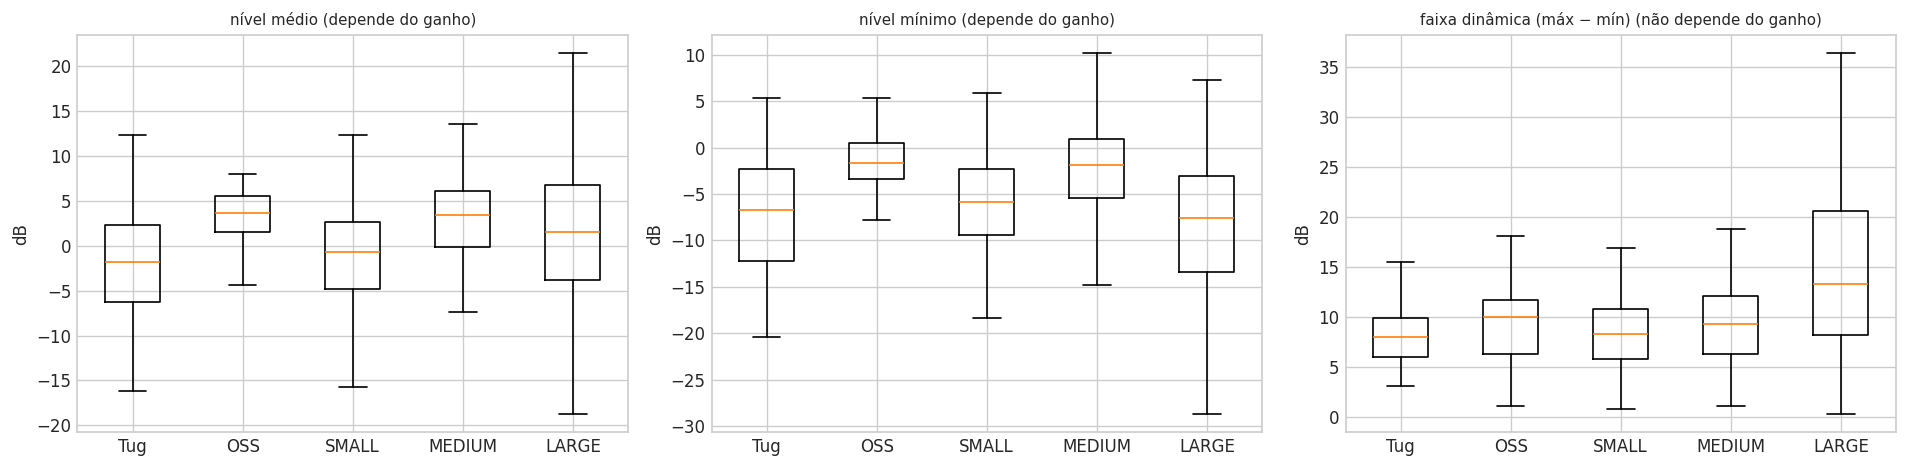

In [5]:
# Nível por gravação a partir dos blocos de 10 s do psd24k (1–8 kHz): médio, máximo (perto do CPA), mínimo (trecho
# mais silencioso) e faixa dinâmica (máximo − mínimo, p90 − p10). O nível absoluto está em unidades do arquivo (16 bits):
# o IARA não fornece a calibração nem qual hidrofone gravou cada arquivo, e as sensibilidades dos hidrofones do projeto
# vão de −200 a −150 dB re 1 V/µPa. As diferenças (faixa dinâmica) não dependem do ganho.
CB = os.path.join(PROC, 'cache_psd24k_niveis.pkl')
if os.path.exists(CB):
    NV = pd.read_pickle(CB)
else:
    _r = {}
    for f in os.listdir(os.path.join(PROC, 'psd24k')):
        if not f.endswith('.pkl'):
            continue
        d = pd.read_pickle(os.path.join(PROC, 'psd24k', f)); kk = (d['freqs'] >= 1000) & (d['freqs'] < 8000)
        lv = 10 * np.log10((10 ** (d['blocos_db'][:, kk] / 10)).mean(1))
        _r[int(f[:-4])] = {'nível médio': 10 * np.log10((10 ** (lv / 10)).mean()), 'nível máximo': lv.max(), 'nível mínimo': lv.min(),
                           'faixa dinâmica (máx − mín)': lv.max() - lv.min(), 'faixa dinâmica (p90 − p10)': np.percentile(lv, 90) - np.percentile(lv, 10)}
    NV = pd.DataFrame(_r).T; NV.to_pickle(CB)
MEDIDAS = list(NV.columns)
NVn = NV.join(meta[['Ship ID', 'Dataset']], how='inner')
def por_navio(ids):
    x = NVn.loc[[i for i in ids if i in NVn.index]]
    return x.groupby('Ship ID').agg(**{m: (m, 'median') for m in MEDIDAS}, ds=('Dataset', lambda s: s.mode()[0]))
_rows = []
for a, b in PARES:
    A, B = por_navio(GRUPOS[a]), por_navio(GRUPOS[b])
    for m in MEDIDAS:
        U, p = mannwhitneyu(A[m], B[m])
        r = {'comparação': f'{a} × {b}', 'medida': m, 'mediana a': A[m].median(), 'mediana b': B[m].median(),
             'AUC (a > b)': U / (len(A) * len(B)), 'p': p, 'depende do ganho?': 'não' if 'dinâmica' in m else 'sim'}
        for ds in 'ACD':                                               # dentro do subconjunto (mesmas condições de seleção)
            x, y = A[A.ds == ds][m], B[B.ds == ds][m]
            r[f'AUC em {ds}'] = (mannwhitneyu(x, y).statistic / (len(x) * len(y))) if min(len(x), len(y)) >= 5 else np.nan
        _rows.append(r)
NIVEL_T = pd.DataFrame(_rows).set_index(['comparação', 'medida'])
display(NIVEL_T.round(3))

_n = por_navio(GRUPOS['SMALL'].union(GRUPOS['MEDIUM']).union(GRUPOS['LARGE'])).join(meta.drop_duplicates('Ship ID').set_index('Ship ID')[['Length']])
RHO_DIN = spearmanr(_n['faixa dinâmica (máx − mín)'], _n.Length, nan_policy='omit')
RHO_MED = spearmanr(_n['nível médio'], _n.Length, nan_policy='omit')
print(f"Por navio: ρ(faixa dinâmica, comprimento) = {RHO_DIN[0]:.3f} (p = {RHO_DIN[1]:.1e}); ρ(nível médio, comprimento) = {RHO_MED[0]:.3f} (p = {RHO_MED[1]:.1e})")
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for j, m in enumerate(('nível médio', 'nível mínimo', 'faixa dinâmica (máx − mín)')):
    dados = [por_navio(GRUPOS[g])[m] for g in ('Tug (SMALL)', 'OSS (MEDIUM)', 'SMALL', 'MEDIUM', 'LARGE')]
    ax[j].boxplot(dados, showfliers=False); ax[j].set_xticks(range(1, 6)); ax[j].set_xticklabels(['Tug', 'OSS', 'SMALL', 'MEDIUM', 'LARGE'])
    ax[j].set_title(m + (' (não depende do ganho)' if 'dinâmica' in m else ' (depende do ganho)'), fontsize=9); ax[j].set_ylabel('dB')
plt.tight_layout(); plt.show()

**Leitura.**
- **Nível médio** (depende do ganho): OSS × Tug 3,7 × -1,8 dB (AUC 0,77, p < 0,001; por subconjunto: A: 0,80, C: 0,84, D: 0,76); MEDIUM × SMALL 3,4 × -0,7 dB (AUC 0,70, p < 0,001; por subconjunto: A: 0,76, C: 0,73, D: 0,68).
- **Nível mínimo**, o trecho mais silencioso da gravação (depende do ganho e do ruído ambiente local): OSS × Tug -1,7 × -6,7 dB (AUC 0,74, p < 0,001; por subconjunto: A: 0,74, C: 0,81, D: 0,70); MEDIUM × SMALL -1,8 × -5,9 dB (AUC 0,70, p < 0,001; por subconjunto: A: 0,76, C: 0,63, D: 0,72).
- **Faixa dinâmica da passagem** (não depende do ganho): OSS × Tug 10,0 × 8,0 dB (AUC 0,59, p = 0,165; por subconjunto: A: 0,68, C: 0,52, D: 0,63); MEDIUM × SMALL 9,3 × 8,3 dB (AUC 0,55, p = 0,269; por subconjunto: A: 0,64, C: 0,71, D: 0,47); LARGE × MEDIUM 13,3 × 9,3 dB (AUC 0,69, p < 0,001; por subconjunto: A: 0,72, C: 0,69, D: 0,58).
- **Leitura conjunta:** os OSS e as MEDIUM chegam ao arquivo mais altos que os rebocadores e as SMALL, mas a diferença aparece igual no **trecho mais silencioso** da gravação, que reflete sobretudo o equipamento e o ruído do local, não o navio; e não se sustenta na faixa dinâmica, que não depende do ganho (não significativa e com sentido diferente entre subconjuntos). A explicação mais provável é **instrumental ou de local**: esses tipos de navio teriam sido gravados mais vezes com outro hidrofone, ganho ou ponto de instalação. Sem a calibração e o hidrofone de cada gravação, o nível absoluto não pode ser usado como pista de porte.
- **A faixa dinâmica separa as LARGE** (13,3 × 9,3 dB contra as MEDIUM, AUC 0,69) e cresce com o comprimento (ρ = 0,40, p < 0,001): navios grandes variam mais de nível durante a passagem. O nível médio acompanha o comprimento só fracamente (ρ = 0,12).

## 5. MEL do pipeline

O MEL é o mesmo espectro de potência agrupado em bandas mel (mais finas no grave e mais largas no agudo). Não pode conter mais informação que o psd24k, mas é a representação que os modelos MEL usam. Número de faixas com q < 0,05, juntando os subconjuntos e dentro de A, C e D:

In [6]:
# MEL do pipeline (src/iara/processing/analysis.py: log_melgram): 256 bandas mel até 8 kHz (decimação 3), em dB com
# librosa.power_to_db(ref=np.max), ou seja, relativo ao máximo da própria gravação. Duas versões processadas:
# sem normalização (log_melgram_d505…) e com normalização L2 por janela (log_melgram_a68e…, a entrada dos modelos MEL).
CM = os.path.join(PROC, 'cache_mel_espectro_medio.pkl')
if os.path.exists(CM):
    _m = pd.read_pickle(CM)
else:
    _m = {}
    for nome, d in (('sem normalização', 'log_melgram_d50517371dbc579e9074fcd15aa81e4f'), ('L2 (modelos)', 'log_melgram_a68edc75124f6c2ae6f093281fb42a9a')):
        _m[nome] = pd.DataFrame({int(f[:-4]): pd.read_pickle(os.path.join(PROC, d, f))['df'].values.mean(0)
                                 for f in os.listdir(os.path.join(PROC, d)) if f.endswith('.pkl')}).T.sort_index()
    pd.to_pickle(_m, CM)
import librosa
FM = librosa.mel_frequencies(n_mels=258, fmin=0, fmax=8000)[1:-1]          # centro aproximado das 256 bandas
MEL_REPS = {'MEL sem normalização (relativo ao máximo da gravação)': _m['sem normalização'],
            'MEL forma (sem a média da gravação)': _m['sem normalização'].sub(_m['sem normalização'].mean(1), axis=0),
            'MEL L2 (entrada dos modelos)': _m['L2 (modelos)']}

def por_subconjunto(X, pares, ncols):
    # Mann-Whitney por faixa (médias por navio) + FDR, juntando os subconjuntos e dentro de A, C e D
    rows = []
    for nome, Xr in X.items():
        for a, b in pares:
            for ds in (None, 'A', 'C', 'D'):
                ia = [i for i in GRUPOS[a] if ds is None or meta.loc[i, 'Dataset'] == ds]
                ib = [i for i in GRUPOS[b] if ds is None or meta.loc[i, 'Dataset'] == ds]
                A, B = nav(Xr, ia), nav(Xr, ib)
                cols = A.columns[A.notna().all() & B.notna().all()]
                if min(len(A), len(B)) < 5:
                    continue
                U, p = mannwhitneyu(A[cols].values, B[cols].values, axis=0); q = false_discovery_control(p)
                rows.append({'representação': nome, 'comparação': f'{a} × {b}', 'subconjunto': ds or 'todos',
                             'navios': f'{len(A)} × {len(B)}', 'faixas com q < 0,05': int((q < 0.05).sum()), 'de': len(cols)})
    return pd.DataFrame(rows).set_index(['representação', 'comparação', 'subconjunto'])
MEL_T = por_subconjunto(MEL_REPS, PARES, 256)
display(MEL_T.unstack('subconjunto')['faixas com q < 0,05'][['todos', 'A', 'C', 'D']])

# onde ficam as faixas da forma do MEL que diferem entre OSS e Tug juntando os subconjuntos
_X = MEL_REPS['MEL forma (sem a média da gravação)']
_A, _B = nav(_X, GRUPOS['OSS (MEDIUM)']), nav(_X, GRUPOS['Tug (SMALL)'])
_U, _p = mannwhitneyu(_A.values, _B.values, axis=0); _q = false_discovery_control(_p)
MEL_SIG = pd.DataFrame({'frequência (Hz)': FM, 'Δ OSS − Tug (dB)': _A.values.mean(0) - _B.values.mean(0), 'q': _q})[_q < 0.05]
print('Forma do MEL, OSS × Tug, todos os subconjuntos juntos: faixas com q < 0,05'); display(MEL_SIG.round(3))

/usr/local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


subconjunto                                                                    todos    A    C    D
representação                                      comparação                                      
MEL L2 (entrada dos modelos)                       LARGE × MEDIUM                241  236  234  206
                                                   MEDIUM × SMALL                  0    0    0    0
                                                   OSS (MEDIUM) × Tug (SMALL)      0    0    0    0
MEL forma (sem a média da gravação)                LARGE × MEDIUM                236  231  234   19
                                                   MEDIUM × SMALL                  0    0    0    0
                                                   OSS (MEDIUM) × Tug (SMALL)     14    0    0    0
MEL sem normalização (relativo ao máximo da gra... LARGE × MEDIUM                253  252  178  234
                                                   MEDIUM × SMALL                  0    0    0    0
                                                   OSS (MEDIUM) × Tug (SMALL)    231    0    0    0

Forma do MEL, OSS × Tug, todos os subconjuntos juntos: faixas com q < 0,05


,frequência (Hz),Δ OSS − Tug (dB),q
87,1034.452,1.678,0.043
91,1085.768,1.666,0.043
92,1098.990,1.741,0.039
134,1827.151,1.218,0.044
135,1849.402,1.203,0.044
136,1871.923,1.251,0.040
137,1894.718,1.307,0.039
138,1917.791,1.155,0.044
250,7439.605,-4.170,0.044
251,7530.201,-4.784,0.043


**Leitura.**
- OSS × Tug: MEL sem normalização, 231 juntando os subconjuntos; 0 em A, 0 em C, 0 em D; forma, 14 juntando os subconjuntos; 0 em A, 0 em C, 0 em D; **L2 (entrada dos modelos), 0 juntando os subconjuntos; 0 em A, 0 em C, 0 em D**.
- O MEL "sem normalização" do pipeline não é nível absoluto: é convertido em dB com referência ao máximo da própria gravação (`power_to_db(ref=np.max)`). As faixas da forma que diferem juntando os subconjuntos ficam em 1.034, 1.086, 1.099, 1.827, 1.849, 1.872, 1.895, 1.918 Hz e em 7.440–7.904 Hz, acima do corte do filtro de decimação (6,4 kHz), onde o sinal chega muito atenuado e perto do piso de −80 dB do MEL.
- **Dentro de cada subconjunto, nenhuma versão do MEL separa OSS de rebocadores.** O que aparece juntando os subconjuntos vem da mistura de condições de gravação, como no nível (Seção 4).

## 6. HHT do projeto: espectro e intermitência

A HHT decompõe o sinal em modos intrínsecos (EMD) e mede a energia instantânea em cada frequência. Além do espectro marginal, o HHT 2D guarda como a energia **varia dentro da janela**, em passos de 80 ms. Daí tiramos a **intermitência** de cada faixa (coeficiente de variação ao longo do tempo), uma informação que os espectros médios descartam e que não depende do ganho.

subconjunto                                                              todos    A   C    D
representação                                comparação                                     
HHT 1D (espectro marginal, log)              LARGE × MEDIUM                247  242  17  109
                                             MEDIUM × SMALL                  0    0   0    0
                                             OSS (MEDIUM) × Tug (SMALL)     49    0   0    0
HHT 1D forma (sem a média)                   LARGE × MEDIUM                124  103  94   82
                                             MEDIUM × SMALL                 89    0   0    0
                                             OSS (MEDIUM) × Tug (SMALL)      0    0   0    0
HHT 2D espectro médio                        LARGE × MEDIUM                123  120  75   82
                                             MEDIUM × SMALL                  0    0   0    0
                                             OSS (MEDIUM) × Tug (SMALL)     60    0   0    0
HHT 2D intermitência (CV em passos de 80 ms) LARGE × MEDIUM                 94  111  40   62
                                             MEDIUM × SMALL                  0    0   0    0
                                             OSS (MEDIUM) × Tug (SMALL)     17    0   6    0

Intermitência, OSS × Tug: 17 de 80 faixas com q < 0,05


,frequência (Hz),CV OSS,CV Tug,AUC (OSS > Tug),q
13,105.469,0.407,0.481,0.332,0.050
14,113.281,0.407,0.492,0.306,0.022
15,121.094,0.411,0.498,0.300,0.019
16,128.906,0.415,0.512,0.282,0.011
17,136.719,0.423,0.529,0.268,0.007
18,144.531,0.430,0.554,0.260,0.007
19,152.344,0.443,0.564,0.261,0.007
20,160.156,0.455,0.577,0.260,0.007
21,167.969,0.467,0.577,0.265,0.007
22,175.781,0.483,0.597,0.273,0.007


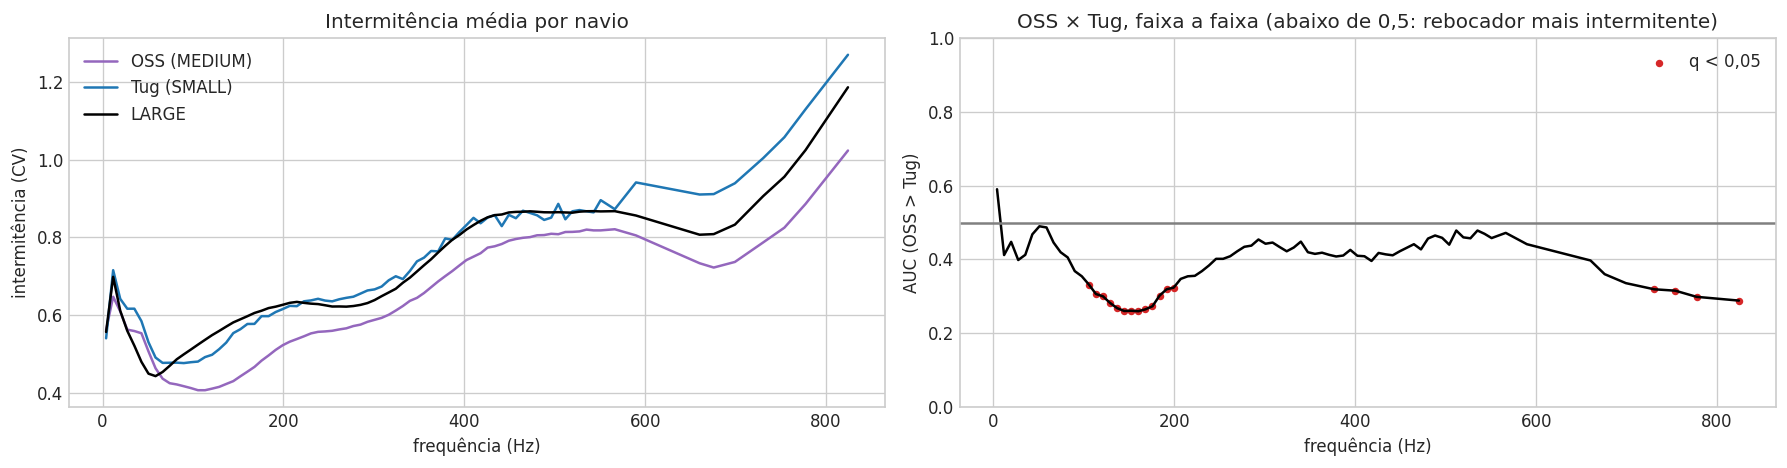

AUC todos  p todos  AUC A    p A  AUC B    p B  AUC C    p C  AUC D    p D
região     comparação                                                                                            
100–200 Hz OSS (MEDIUM) × Tug (SMALL)      0.275    0.001  0.373  0.212  0.244  0.055  0.172  0.004  0.435  0.474
           MEDIUM × SMALL                  0.426    0.098  0.397  0.136  0.417  0.327  0.411  0.195  0.443  0.349
720–830 Hz OSS (MEDIUM) × Tug (SMALL)      0.303    0.003  0.308  0.058  0.269  0.087  0.311  0.102  0.442  0.520
           MEDIUM × SMALL                  0.387    0.011  0.340  0.021  0.383  0.169  0.385  0.093  0.444  0.361

Validação em metades (200 sorteios): mesmo sentido em 95%, p < 0,05 em 46%, AUC mediana 0.32


,vezes escolhida
faixa escolhida (Hz),
824.0,42
160.0,27
145.0,25
168.0,18
137.0,17


In [7]:
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)
# HHT do projeto: sinal decimado para 2 kHz, janelas de 2,56 s a cada 5,12 s, EMD com 8 IMFs e energia instantânea
# acumulada por frequência (0–1 kHz), normalizada pelo pico da janela.
#  - HHT 1D (hht_features): espectro marginal de Hilbert, 256 faixas;
#  - HHT 2D (hht_2d_features): o mesmo com o tempo dentro da janela (32 passos de 80 ms × 128 faixas).
# Do HHT 2D tiramos uma medida que os espectros médios descartam: a INTERMITÊNCIA de cada faixa, o coeficiente de
# variação da energia ao longo dos passos de 80 ms (sem 2 passos em cada borda, por efeito de extremidade).
# Como cada janela é normalizada pelo seu pico, nenhuma dessas medidas depende do ganho.
CH = os.path.join(PROC, 'cache_hht_resumo.pkl')
if os.path.exists(CH):
    _h = pd.read_pickle(CH)
else:
    m1, m2, cv2 = {}, {}, {}
    for f in os.listdir(os.path.join(PROC, 'hht_features')):
        if f.endswith('.pkl'):
            d = pd.read_pickle(os.path.join(PROC, 'hht_features', f)); m1[int(f[:-4])] = np.log10(d['df'].values.mean(0) + 1e-6)
    for f in os.listdir(os.path.join(PROC, 'hht_2d_features')):
        if f.endswith('.pkl'):
            S2 = pd.read_pickle(os.path.join(PROC, 'hht_2d_features', f))['spectrograms'][:, 2:-2, :]
            m2[int(f[:-4])] = S2.mean((0, 1))
            mu, sd = S2.mean(1), S2.std(1)
            cv2[int(f[:-4])] = np.nanmean(np.where(mu > 1e-3, sd / (mu + 1e-9), np.nan), axis=0)
    _h = {'hht1d_log': pd.DataFrame(m1).T.sort_index(), 'hht2d_medio': pd.DataFrame(m2).T.sort_index(), 'hht2d_cv': pd.DataFrame(cv2).T.sort_index()}
    pd.to_pickle(_h, CH)
F2 = np.linspace(0, 1000, 129)[:-1] + 1000 / 256                  # centro das 128 faixas do HHT 2D
HHT_REPS = {'HHT 1D (espectro marginal, log)': _h['hht1d_log'],
            'HHT 1D forma (sem a média)': _h['hht1d_log'].sub(_h['hht1d_log'].mean(1), axis=0),
            'HHT 2D espectro médio': _h['hht2d_medio'],
            'HHT 2D intermitência (CV em passos de 80 ms)': _h['hht2d_cv']}
HHT_T = por_subconjunto(HHT_REPS, PARES, 0)
display(HHT_T.unstack('subconjunto')['faixas com q < 0,05'][['todos', 'A', 'C', 'D']])

# Intermitência OSS × Tug, faixa a faixa (só faixas com energia em todas as gravações)
CV = _h['hht2d_cv']
_A, _B = nav(CV, GRUPOS['OSS (MEDIUM)']), nav(CV, GRUPOS['Tug (SMALL)'])
OKF = (_A.notna().all() & _B.notna().all()).values
_U, _p = mannwhitneyu(_A.loc[:, OKF].values, _B.loc[:, OKF].values, axis=0); _q = false_discovery_control(_p)
CV_SIG = pd.DataFrame({'frequência (Hz)': F2[OKF], 'CV OSS': _A.loc[:, OKF].mean().values, 'CV Tug': _B.loc[:, OKF].mean().values,
                       'AUC (OSS > Tug)': _U / (len(_A) * len(_B)), 'q': _q})[_q < 0.05]
print(f'Intermitência, OSS × Tug: {len(CV_SIG)} de {OKF.sum()} faixas com q < 0,05'); display(CV_SIG.round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for g, cor in (('OSS (MEDIUM)', 'tab:purple'), ('Tug (SMALL)', 'tab:blue'), ('LARGE', 'k')):
    ax[0].plot(F2[OKF], nav(CV, GRUPOS[g]).loc[:, OKF].mean().values, color=cor, label=g)
ax[0].set_xlabel('frequência (Hz)'); ax[0].set_ylabel('intermitência (CV)'); ax[0].legend(); ax[0].set_title('Intermitência média por navio')
ax[1].plot(F2[OKF], _U / (len(_A) * len(_B)), color='k'); ax[1].axhline(0.5, color='gray')
ax[1].scatter(CV_SIG['frequência (Hz)'], CV_SIG['AUC (OSS > Tug)'], color='tab:red', s=12, label='q < 0,05')
ax[1].set_ylim(0, 1); ax[1].set_xlabel('frequência (Hz)'); ax[1].set_ylabel('AUC (OSS > Tug)'); ax[1].legend()
ax[1].set_title('OSS × Tug, faixa a faixa (abaixo de 0,5: rebocador mais intermitente)')
plt.tight_layout(); plt.show()

# Por subconjunto, nas duas regiões que apareceram (escolhidas olhando os dados: só servem para ver o sentido)
_rows = []
for lo, hi in ((100, 200), (720, 830)):
    b = CV.loc[:, (F2 >= lo) & (F2 < hi)].mean(1)
    for a_, b_ in PARES[:2]:
        r = {'região': f'{lo}–{hi} Hz', 'comparação': f'{a_} × {b_}'}
        for ds in (None, 'A', 'B', 'C', 'D'):
            ia = [i for i in GRUPOS[a_] if i in b.index and (ds is None or meta.loc[i, 'Dataset'] == ds)]
            ib = [i for i in GRUPOS[b_] if i in b.index and (ds is None or meta.loc[i, 'Dataset'] == ds)]
            x, y = b.loc[ia].groupby(meta.loc[ia, 'Ship ID'].values).mean(), b.loc[ib].groupby(meta.loc[ib, 'Ship ID'].values).mean()
            if min(len(x), len(y)) >= 5:
                U, p = mannwhitneyu(x, y); r[f'AUC {ds or "todos"}'] = U / (len(x) * len(y)); r[f'p {ds or "todos"}'] = p
        _rows.append(r)
CV_DS = pd.DataFrame(_rows).set_index(['região', 'comparação'])
display(CV_DS.round(3))

# Validação em metades de navios: na metade de descoberta escolhe-se a faixa de menor p; na outra metade, que não
# participou da escolha, mede-se essa faixa. 200 sorteios.
_rng = np.random.default_rng(0); _res = []
_so = np.array(sorted(set(meta.loc[GRUPOS['OSS (MEDIUM)'], 'Ship ID']))); _st = np.array(sorted(set(meta.loc[GRUPOS['Tug (SMALL)'], 'Ship ID'])))
def _sel(ids, navios):
    return [i for i in ids if i in CV.index and meta.loc[i, 'Ship ID'] in navios]
for _ in range(200):
    ho, ht = _rng.permutation(_so), _rng.permutation(_st)
    do, vo = set(ho[:len(ho) // 2]), set(ho[len(ho) // 2:]); dt, vt = set(ht[:len(ht) // 2]), set(ht[len(ht) // 2:])
    Ad, Bd = nav(CV, _sel(GRUPOS['OSS (MEDIUM)'], do)).loc[:, OKF], nav(CV, _sel(GRUPOS['Tug (SMALL)'], dt)).loc[:, OKF]
    Ud, pd_ = mannwhitneyu(Ad.values, Bd.values, axis=0); j = int(np.argmin(pd_)); sinal = Ud[j] / (len(Ad) * len(Bd)) > 0.5
    Av, Bv = nav(CV, _sel(GRUPOS['OSS (MEDIUM)'], vo)).loc[:, OKF], nav(CV, _sel(GRUPOS['Tug (SMALL)'], vt)).loc[:, OKF]
    Uv, pv_ = mannwhitneyu(Av.values[:, j], Bv.values[:, j]); av = Uv / (len(Av) * len(Bv))
    _res.append({'faixa escolhida (Hz)': F2[OKF][j], 'AUC na validação': av, 'p na validação': pv_, 'mesmo sentido': (av > 0.5) == sinal})
VAL_CV = pd.DataFrame(_res)
print(f"Validação em metades (200 sorteios): mesmo sentido em {100 * VAL_CV['mesmo sentido'].mean():.0f}%, "
      f"p < 0,05 em {100 * (VAL_CV['p na validação'] < 0.05).mean():.0f}%, AUC mediana {VAL_CV['AUC na validação'].median():.2f}")
display(VAL_CV['faixa escolhida (Hz)'].round(0).value_counts().head(5).rename('vezes escolhida').to_frame())

**Leitura.**
- **Espectro marginal (1D, inclusive a forma) e espectro médio do HHT 2D:** as diferenças OSS × Tug aparecem só juntando os subconjuntos e somem dentro de cada um (0 faixas em A, C e D), como no MEL.
- **Intermitência:** 17 de 80 faixas com q < 0,05 entre OSS e Tug, em 105–199 Hz e 730–824 Hz: os rebocadores têm intermitência maior. A Seção 6.1 mostra o que isso significa de fato.
- **Por subconjunto** (região de 100–200 Hz): AUC (OSS > Tug) de 0,37 em A, 0,24 em B, 0,17 em C, 0,44 em D. O sentido é o mesmo nos quatro subconjuntos, mais forte em B e C. As regiões foram escolhidas olhando os dados, então esta tabela só mostra a consistência do sentido.
- **Validação em metades de navios** (faixa escolhida numa metade, medida na outra): mesmo sentido em 95% dos 200 sorteios, mas p < 0,05 em só 46% (AUC mediana 0,32). O sentido se confirma; a força, com ~23 OSS e ~17 rebocadores por metade, é limitada.
- **MEDIUM × SMALL:** mesmo sentido, mais fraco (720–830 Hz: AUC 0,39, p = 0,011).

### 6.1 Intermitência ou energia relativa?

O HHT 2D normaliza cada janela pelo seu pico. Numa faixa fraca em relação ao componente dominante, a média é pequena e o coeficiente de variação cresce só por causa do denominador. Se for isso, a intermitência mede **quanto a faixa é fraca em relação ao componente mais forte**, e não quanto a energia oscila no tempo:

In [8]:
# A intermitência mede dinâmica no tempo ou só energia relativa? O HHT 2D normaliza cada janela pelo seu pico: uma faixa
# fraca em relação ao componente dominante tem média pequena, e o coeficiente de variação (desvio ÷ média) cresce por
# causa do denominador. Comparamos a intermitência com a energia relativa da mesma faixa e com a banda LOFAR 31–86 Hz.
from scipy.stats import spearmanr
_S = pd.read_pickle(os.path.join(PROC, 'cache_lofar_espectro_medio.pkl')); _F = (np.arange(1024) + 1) * 16000 / 2048
MU = _h['hht2d_medio']
_ids = [i for i in meta.index if i in CV.index and i in _S.index]
_k = (F2 >= 100) & (F2 < 200)
cv_b, en_b = CV.loc[_ids, _k].mean(1), np.log(MU.loc[_ids, _k].mean(1))
banda = _S.loc[_ids, (_F >= 31) & (_F < 86)].mean(1)
_coef = np.polyfit(en_b, cv_b, 1); resid = cv_b - np.polyval(_coef, en_b)
REL = {'ρ(intermitência, energia relativa)': spearmanr(cv_b, en_b)[0],
       'ρ(banda LOFAR, intermitência)': spearmanr(banda, cv_b)[0],
       'ρ(banda LOFAR, energia relativa)': spearmanr(banda, en_b)[0],
       'ρ(banda LOFAR, resíduo da intermitência)': spearmanr(banda, resid)[0]}
print('100–200 Hz, todas as gravações de navio (Spearman):'); display(pd.Series(REL).round(2).to_frame('ρ'))
_rows = []
for nome, v in (('intermitência', cv_b), ('energia relativa (log)', en_b), ('intermitência sem o efeito da energia relativa (resíduo)', resid)):
    a = v.loc[[i for i in GRUPOS['OSS (MEDIUM)'] if i in v.index]]; b = v.loc[[i for i in GRUPOS['Tug (SMALL)'] if i in v.index]]
    a = a.groupby(meta.loc[a.index, 'Ship ID'].values).mean(); b = b.groupby(meta.loc[b.index, 'Ship ID'].values).mean()
    U, p = mannwhitneyu(a, b); _rows.append({'medida (100–200 Hz)': nome, 'AUC (OSS > Tug)': U / (len(a) * len(b)), 'p': p})
RES_EN = pd.DataFrame(_rows).set_index('medida (100–200 Hz)')
print('OSS × Tug, por navio:'); display(RES_EN.round(3))

100–200 Hz, todas as gravações de navio (Spearman):


,ρ
"ρ(intermitência, energia relativa)",-0.92
"ρ(banda LOFAR, intermitência)",0.64
"ρ(banda LOFAR, energia relativa)",-0.68
"ρ(banda LOFAR, resíduo da intermitência)",0.30


OSS × Tug, por navio:


,AUC (OSS > Tug),p
medida (100–200 Hz),,
intermitência,0.275,0.001
energia relativa (log),0.710,0.001
intermitência sem o efeito da energia relativa (resíduo),0.368,0.045


**Leitura.**
- Em 100–200 Hz, a intermitência e a energia relativa da mesma faixa têm ρ = -0,92: **a intermitência é, quase toda, a energia relativa com o sinal trocado**. A banda LOFAR de 31–86 Hz se relaciona com as duas (ρ = 0,64 com a intermitência e -0,68 com a energia relativa): quando a banda grave domina, as outras faixas ficam relativamente fracas e a "intermitência" sobe.
- **OSS × Tug:** a energia relativa em 100–200 Hz separa tanto quanto a intermitência (AUC 0,71, p = 0,001); o que sobra da intermitência depois de descontar a energia relativa é fraco (AUC 0,37, p = 0,045, um teste entre muitos).
- **Correção da leitura anterior:** a diferença não é que os rebocadores "oscilem mais no tempo". É que os OSS têm **relativamente mais energia em 100–200 Hz** em relação ao componente dominante; coerente com o pico dominante deles cair mais vezes em 86–150 Hz. É uma diferença de **balanço espectral**, fraca e exploratória (testamos muitas representações até achá-la).

## 7. Existe uma pista positiva de SMALL? SMALL × LARGE e SMALL × BACKGROUND (psd24k)

As seções anteriores compararam SMALL com MEDIUM. A pergunta agora é outra: há algo no espectro cru que **só o SMALL tem**, em comparação com LARGE e BACKGROUND? O LOFAR usa o TPSW, que achata ruído largo e contínuo (por exemplo, o chiado de hélice rápida); o psd24k não tem esse achatamento.

**Medidas** (todas independentes do ganho, já que o nível do IARA não é calibrado), em `scratch/small_assinatura/psd24k_small.py`:
- **forma:** média em dB de cada oitava (31 Hz–24 kHz) menos a média da gravação em 125 Hz–16 kHz;
- **inclinação** (dB por oitava) em 125 Hz–8 kHz e em 1–16 kHz;
- **variação na passagem:** p90 − p10 dos blocos de 10 s, por oitava.

**Unidade:** o navio. Cada medida é centrada na mediana do seu subconjunto (A–D, remove a resposta do hidrofone/local) e resumida pela mediana do navio; Mann-Whitney com FDR. O BACKGROUND está todo no subconjunto E: a comparação com ele usa valores **não centrados** e mistura classe com equipamento.

Por navio, centrado no subconjunto; AUC = P(1º grupo > 2º). BACKGROUND (subconjunto E) sem centrar.


,SMALL med,MEDIUM med,LARGE med,AUC SMALL×LARGE,q S×L,AUC MEDIUM×LARGE,AUC SMALL×BG (bruto),q S×BG,AUC LARGE×BG (bruto)
medida,,,,,,,,,
forma 31.25–62 Hz,-2.656,-2.291,5.934,0.260,0.000,0.264,0.757,0.000,0.854
forma 62.5–125 Hz,-1.428,-1.080,3.202,0.331,0.000,0.325,0.652,0.000,0.747
forma 125–250 Hz,-0.962,-0.830,3.188,0.385,0.001,0.381,0.530,0.445,0.621
forma 250–500 Hz,0.649,-0.870,4.274,0.387,0.001,0.366,0.495,0.885,0.623
forma 500–1000 Hz,0.000,0.113,3.397,0.368,0.000,0.368,0.605,0.004,0.718
forma 1000–2000 Hz,-0.245,0.070,1.340,0.421,0.023,0.427,0.778,0.000,0.823
forma 2000–4000 Hz,0.354,-0.110,0.737,0.448,0.132,0.419,0.630,0.000,0.696
forma 4000–8000 Hz,0.049,-0.033,-0.230,0.599,0.005,0.577,0.454,0.229,0.405
forma 8000–16000 Hz,0.028,0.073,-0.590,0.581,0.021,0.606,0.349,0.000,0.261


AUC (tipo de SMALL > LARGE), por navio:


tipo,Fishing Vessel,Pilot Vessel,Tug
medida,,,
forma 31.25–62 Hz,0.33,0.23,0.27
forma 62.5–125 Hz,0.42,0.40,0.30
forma 125–250 Hz,0.45,0.46,0.33
forma 250–500 Hz,0.45,0.43,0.36
forma 500–1000 Hz,0.46,0.39,0.34
forma 1000–2000 Hz,0.54,0.40,0.37
forma 2000–4000 Hz,0.50,0.55,0.37
forma 4000–8000 Hz,0.56,0.61,0.61
forma 8000–16000 Hz,0.47,0.54,0.65


AUC SMALL × LARGE dentro de cada subconjunto:


subconjunto,A,B,C,D
medida,,,,
forma 31.25–62 Hz,0.20,0.39,0.16,0.38
forma 62.5–125 Hz,0.29,0.44,0.24,0.44
forma 125–250 Hz,0.34,0.50,0.25,0.48
forma 250–500 Hz,0.36,0.54,0.24,0.48
forma 500–1000 Hz,0.33,0.50,0.26,0.49
forma 1000–2000 Hz,0.35,0.53,0.34,0.52
forma 2000–4000 Hz,0.43,0.48,0.38,0.51
forma 4000–8000 Hz,0.61,0.44,0.66,0.53
forma 8000–16000 Hz,0.62,0.54,0.67,0.49


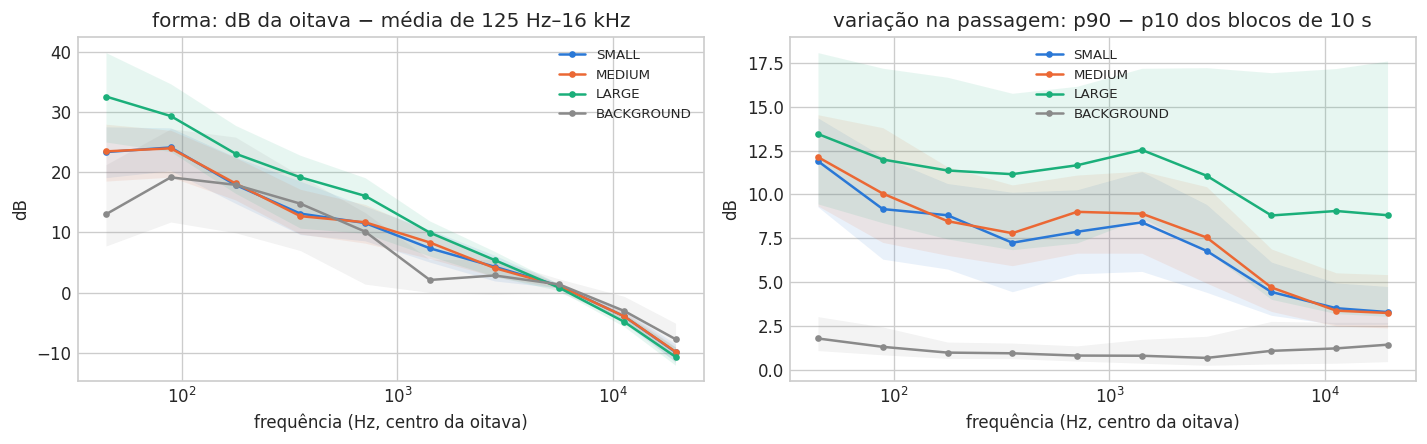

In [9]:
# Seção 7: pista POSITIVA de SMALL no psd24k? Roda scratch/small_assinatura/psd24k_small.py (escreve os CSVs) e lê o resultado.
import runpy, contextlib, io
_cwd = os.getcwd(); os.chdir(R.ROOT)
try:
    with contextlib.redirect_stdout(io.StringIO()):
        runpy.run_path('scratch/small_assinatura/psd24k_small.py', run_name='__main__')
finally:
    os.chdir(_cwd)
_rep = os.path.join(R.ROOT, 'reports', 'small_medium', 'psd24k_small')
SM_X = pd.read_csv(_rep + '_medidas.csv', index_col=0)
SM_T = pd.read_csv(_rep + '_testes.csv').set_index('medida')
SM_PT = pd.read_csv(_rep + '_por_tipo.csv').pivot(index='medida', columns='tipo', values='AUC vs LARGE').loc[SM_T.index]
SM_PS = pd.read_csv(_rep + '_por_subconjunto.csv').pivot(index='medida', columns='subconjunto', values='AUC SMALL×LARGE').loc[SM_T.index]
print('Por navio, centrado no subconjunto; AUC = P(1º grupo > 2º). BACKGROUND (subconjunto E) sem centrar.')
display(SM_T[['SMALL med', 'MEDIUM med', 'LARGE med', 'AUC SMALL×LARGE', 'q S×L', 'AUC MEDIUM×LARGE',
              'AUC SMALL×BG (bruto)', 'q S×BG', 'AUC LARGE×BG (bruto)']].round(3))
print('AUC (tipo de SMALL > LARGE), por navio:'); display(SM_PT.round(2))
print('AUC SMALL × LARGE dentro de cada subconjunto:'); display(SM_PS.round(2))

# figura: forma e variação na passagem, mediana entre navios
_cor = {'SMALL': '#2a78d6', 'MEDIUM': '#eb6834', 'LARGE': '#1baf7a', 'BACKGROUND': '#8a8a8a'}
_fo = [c for c in SM_X.columns if c.startswith('forma')]; _di = [c for c in SM_X.columns if c.startswith('dinâmica')]
_cent = np.r_[[np.sqrt(31.25 * 62.5) * 2 ** k for k in range(9)], np.sqrt(16000 * 24000)]
_nav = SM_X['Ship ID'].astype(str).where(SM_X.classe != 'BACKGROUND', 'bg' + SM_X.index.astype(str))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for c in ['SMALL', 'MEDIUM', 'LARGE', 'BACKGROUND']:
    sel = SM_X.classe == c
    for ax, cols in zip(axs, [_fo, _di]):
        g = SM_X.loc[sel, cols].groupby(_nav[sel]).median()
        ax.plot(_cent, g.median().values, '-o', ms=3, color=_cor[c], label=c)
        ax.fill_between(_cent, g.quantile(.25).values, g.quantile(.75).values, color=_cor[c], alpha=.1, lw=0)
for ax, t in zip(axs, ['forma: dB da oitava − média de 125 Hz–16 kHz', 'variação na passagem: p90 − p10 dos blocos de 10 s']):
    ax.set_xscale('log'); ax.set_xlabel('frequência (Hz, centro da oitava)'); ax.set_ylabel('dB'); ax.set_title(t); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.**
- **SMALL e MEDIUM são iguais contra LARGE em todas as 22 medidas:** a AUC SMALL × LARGE e a AUC MEDIUM × LARGE diferem no máximo 0,06. O que separa o SMALL do LARGE é o mesmo que separa o MEDIUM: é diferença de "navio < 100 m", não de SMALL.
- **SMALL × LARGE:** 20 de 22 medidas com q < 0,05, 16 no sentido "o LARGE tem mais" e 4 no sentido "o SMALL tem mais". O LARGE tem mais grave relativo (31–62 Hz: AUC 0,26), espectro mais inclinado e muito mais variação ao longo da passagem (1–2 kHz: AUC 0,31).
- **A única pista no sentido "SMALL tem mais"** é um espectro mais plano, com relativamente mais energia acima de 4 kHz (inclinação: AUC 0,62; 4–8 kHz: AUC 0,60). É fraca e não se repete em todos os subconjuntos (afastada de 0,5 em A, C) nem em todos os tipos (inclinação, por tipo: Pilot Vessel 0,57; Tug 0,66; Fishing Vessel 0,56).
- **SMALL × BACKGROUND:** AUCs de 0,26 a 0,97; em 95% das medidas o SMALL fica do mesmo lado do BACKGROUND que o LARGE, só que mais perto: o SMALL é "um navio, só que mais fraco". A variação na passagem separa navio de fundo (AUC ~0,95), o que só diz que há uma fonte passando.
- **Leitura conjunta:** no espectro cru, tudo se resume a um eixo: **o quanto a embarcação se destaca do fundo**. O SMALL não tem uma "cor" espectral própria; tem menos do que o LARGE tem. Sem a distância de cada gravação, "se destaca pouco" pode ser barco pequeno ou barco longe.

## 8. Conclusões

1. **Nas representações espectrais, nada separa Offshore Supply Ships de rebocadores**, nem MEDIUM de SMALL: a forma do espectro até 24 kHz, o DEMON em cinco bandas, a posição das raias estreitas, o MEL e o espectro do HHT dão 0 faixas significativas dentro de cada subconjunto. O indício de raias de rebocador em ~64–80 Hz não sobrevive à correção para múltiplos testes.
2. **O nível absoluto difere, mas não serve:** a diferença aparece também no trecho mais silencioso de cada gravação e não se sustenta na medida que não depende do ganho. Sem calibração nem identificação do hidrofone, ela é mais provavelmente instrumental ou de local do que acústica.
3. **A "intermitência" do HHT 2D separa os dois tipos, mas mede sobretudo energia relativa** (Seção 6.1): os OSS têm relativamente mais energia em 100–200 Hz em relação ao componente dominante. O sentido se repete em todos os subconjuntos e nas metades de navios, mas o efeito é moderado, e o que sobra de dinâmica temporal é marginal. O NB38 testa se essa pista ajuda um classificador a generalizar para navios novos.
4. **Somando LOFAR (NB35), DEMON (NB36) e este notebook:** no conteúdo espectral, um supply de 50–90 m soa como um rebocador de 20–35 m. A fronteira SMALL/MEDIUM do IARA, definida por comprimento, quase não tem correlato acústico nestes dados, coerente com a física (propulsão parecida) e com o fato de nenhum modelo a generalizar para navios novos.
5. **O que distingue as LARGE** aparece em várias representações independentes: banda de 31–86 Hz (LOFAR), modulação forte e grave (DEMON) e maior faixa dinâmica na passagem (psd24k).
6. **Não há pista positiva de SMALL no espectro cru** (Seção 7): contra LARGE, o SMALL só tem "menos do que o LARGE tem" (menos grave relativo, espectro menos inclinado, menos variação na passagem), exatamente como o MEDIUM. A única pista própria, um espectro um pouco mais plano acima de 4 kHz, é fraca e não se repete em todos os subconjuntos e tipos.

**Ressalvas:** 46 OSS e 34 rebocadores dão poder estatístico para diferenças moderadas, não para diferenças pequenas; e "não detectável nestes dados" não é o mesmo que "não existe". Calibração e distância de cada gravação permitiriam usar o nível de fonte, que é a medida física mais direta de porte.